# Análisis exploratorio y limpieza de datos climáticos

**Proyecto en Python | Estación Acatitán, San Ignacio, Sinaloa (CONAGUA)**

Trabajamos con una base de datos histórica que registra precipitación, evaporación y temperaturas máximas y mínimas. Nuestro objetivo es explorar los datos, detectar registros faltantes y completarlos con el promedio de cada variable para comparar los resultados.


## 1. Librerías utilizadas

Utilizamos **Pandas** para leer y organizar los registros en un DataFrame y **Matplotlib** para visualizar los datos con histogramas y un diagrama de caja. Estas herramientas nos ayudan a entender el conjunto de datos antes y después de la limpieza.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Carga de datos: `cargarCSV(ruta)`

El archivo tiene un encabezado descriptivo y después registros separados por espacios. Por eso usamos `skiprows=19` y `sep=r'\s+'`. Damos nombre a cinco columnas: `FECHA`, `PRECIP`, `EVAP`, `TMAX` y `TMIN`. Con `na_values=['Nulo']` indicamos que la palabra *Nulo* representa un dato faltante. También especificamos la codificación del archivo para leerlo correctamente.

El TXT original termina con una línea formada solamente por guiones. **La eliminamos desde Python, sin alterar el archivo:** comprobamos si la última fila contiene guiones y, si es así, usamos `df.iloc[:-1].copy()` para quedarnos con los registros anteriores. De esta forma, la fila de guiones no se cuenta como si fuera una fecha con datos faltantes.


In [11]:
def cargarCSV(ruta):
    nombre_columnas = ['FECHA', 'PRECIP', 'EVAP', 'TMAX', 'TMIN']
    df = pd.read_csv(ruta,
               sep=r'\s+',
               skiprows=19,
               names=nombre_columnas,
               na_values=['Nulo'],
               encoding='latin-1'
              )

    # Eliminamos la última fila si contiene únicamente guiones.
    # El archivo TXT original se conserva sin cambios.
    if not df.empty and str(df.iloc[-1]['FECHA']).strip('-') == '':
        df = df.iloc[:-1].copy()

    return df

## 3. Exploración inicial: `head()` y `describe()`

Con `head()` mostramos las primeras cinco filas para comprobar cómo se cargó la información. Luego, `describe()` resume los datos numéricos: cantidad de valores registrados, media, desviación estándar, mínimos, máximos y cuartiles. Esto nos da un punto de comparación antes de la limpieza. En los primeros registros de `EVAP` aparecen valores `NaN`, que representan datos faltantes.


In [12]:
# Llamamos a la función y guardamos los datos en la variable 'df'
df = cargarCSV('25001.txt')

#Mostramos la tabla
print("\n--- Vista de la tabla---")
print(df.head())

#Un  describe para ver las estadística
print("\n--- Nuevo Resumen Estadístico---")
print(df.describe())


--- Vista de la tabla---
        FECHA  PRECIP  EVAP  TMAX  TMIN
0  01/01/1961     0.0   NaN  25.0  13.0
1  02/01/1961     0.0   NaN  27.5  14.0
2  03/01/1961     0.0   NaN  31.0  11.0
3  04/01/1961     0.0   NaN  32.0  13.0
4  05/01/1961     0.0   NaN  29.0  14.0

--- Nuevo Resumen Estadístico---
             PRECIP          EVAP          TMAX          TMIN
count  19534.000000  19302.000000  19569.000000  19568.000000
mean       2.217452      4.882157     34.468808     16.657420
std        9.015782      2.279340      3.430054      6.248605
min        0.000000      0.000000     18.000000     -2.500000
25%        0.000000      3.200000     32.500000     11.000000
50%        0.000000      4.500000     35.000000     16.500000
75%        0.000000      6.500000     37.000000     23.000000
max      217.400000     15.600000     45.500000     29.000000


## 4. Identificación de registros incompletos: `contarNulos(df)`

Creamos un diccionario llamado `faltantes` y recorremos las filas con `iterrows()`. Usamos `isnull().any()` para saber si una fila tiene por lo menos un valor faltante e `isnull().sum()` para contar cuántos son. Guardamos la fecha y el número de nulos, y mostramos cinco ejemplos.

Después de descartar la fila de guiones desde el código, encontramos **312 fechas con al menos un valor faltante**. Esto no significa que existan solo 312 celdas vacías, porque una fecha puede contener varios nulos.


In [4]:
# Contar los valores nulos por fecha y por columna
def contarNulos(df):
    print("--- Conteo de registros faltantes por fecha ---")
    faltantes = {}

    for indice, fila in df.iterrows():
        if fila.isnull().any():
            cantidad_nulos = fila.isnull().sum()
            fecha = fila['FECHA']
            faltantes[fecha] = cantidad_nulos

    print(f"Se encontraron {len(faltantes)} fechas con datos faltantes.")
    print("Ejemplo de las primeras 5 fechas:")
    for fecha in list(faltantes.keys())[:5]:
        print(f"Fecha: {fecha} | Faltantes: {faltantes[fecha]}")

    # Contamos los nulos en cada columna, incluyendo FECHA.
    print("\n--- Total de valores nulos por columna ---")
    nulos_por_columna = df.isnull().sum()
    for columna, cantidad in nulos_por_columna.items():
        print(f"{columna}: {cantidad} valores faltantes")

    # Sumamos todos los valores faltantes de la tabla.
    print(f"Total de valores nulos: {nulos_por_columna.sum()}")

## 5. Reconstrucción: `limpiar_datos(df)`

Hacemos una copia con `df.copy()` para conservar los valores originales. Después recorremos las columnas numéricas con un `for`, calculamos la media de cada una mediante `mean()` y reemplazamos los nulos usando `fillna()`. El resultado queda en un nuevo DataFrame.

Los promedios utilizados para completar los registros son aproximadamente **2.22 mm** en precipitación, **4.88 mm** en evaporación, **34.47 °C** en temperatura máxima y **16.66 °C** en temperatura mínima. Estos valores son estimaciones estadísticas: no recuperan las mediciones reales de cada fecha.


In [5]:
def limpiar_datos(df):
    print("Rellenando nulos con la media de la columna")
    
    df_limpio=df.copy()
    columnas_numericas=['PRECIP','EVAP','TMAX','TMIN']
    
    for columna in columnas_numericas:
        media_columna=df_limpio[columna].mean()
        df_limpio[columna] = df_limpio[columna].fillna(media_columna)
        print(f"Columna '{columna}': nulos reemplazados con la media -> {media_columna:.2f} ")
    return df_limpio


## 6. Cómo visualizamos los cambios

Definimos una función para comparar datos originales y datos limpios. Los **histogramas** muestran la distribución de precipitación y evaporación, mientras que el **boxplot** de temperatura máxima permite comparar mediana, dispersión y posibles valores atípicos.

Al rellenar nulos con la media, se añaden observaciones cerca del promedio. Por ello, las gráficas pueden conservar su forma general, pero su distribución y variabilidad pueden cambiar.


In [6]:
def graficar_histogramas_y_boxplots(df_original, df_limpio):
    """Compara la limpieza con dos histogramas y un boxplot."""

    # Histogramas de PRECIP y EVAP: muestran cómo cambia su distribución.
    for columna in ['PRECIP', 'EVAP']:
        fig, ejes = plt.subplots(1, 2, figsize=(10, 4))

        ejes[0].hist(df_original[columna].dropna(), bins=20, edgecolor='black')
        ejes[0].set_title(f'Histograma antes: {columna}')
        ejes[0].set_xlabel(columna)
        ejes[0].set_ylabel('Frecuencia')

        ejes[1].hist(df_limpio[columna].dropna(), bins=20, edgecolor='black')
        ejes[1].set_title(f'Histograma después: {columna}')
        ejes[1].set_xlabel(columna)
        ejes[1].set_ylabel('Frecuencia')

        fig.tight_layout()
        plt.show()

    # Boxplot de TMAX: permite comparar la dispersión y valores atípicos.
    plt.figure(figsize=(7, 4))
    plt.boxplot(
        [df_original['TMAX'].dropna(), df_limpio['TMAX'].dropna()],
        tick_labels=['Antes', 'Después']
    )
    plt.title('Boxplot antes y después: TMAX')
    plt.ylabel('TMAX (°C)')
    plt.show()


## 7. Comparación estadística antes y después

Volvemos a usar `head()` para confirmar que donde había `NaN` ahora hay valores, y `describe()` para comparar los resúmenes. Tras la limpieza, las cuatro columnas numéricas tienen **19,574 valores**. La media se conserva prácticamente igual porque los nulos se sustituyeron precisamente por ese promedio.

Este método puede reducir artificialmente la variabilidad y no considera la época del año ni las condiciones climáticas de cada fecha.


In [13]:
df_lleno = limpiar_datos(df)

#Mostramos la tabla DESPUÉS de llenar
print("\n--- Vista de la tabla DESPUÉS de llenar ---")
print(df_lleno.head())

#Un nuevo describe para ver como cambió la estadística
print("\n--- Nuevo Resumen Estadístico (Post-Limpieza) ---")
print(df_lleno.describe())

Rellenando nulos con la media de la columna
Columna 'PRECIP': nulos reemplazados con la media -> 2.22 
Columna 'EVAP': nulos reemplazados con la media -> 4.88 
Columna 'TMAX': nulos reemplazados con la media -> 34.47 
Columna 'TMIN': nulos reemplazados con la media -> 16.66 

--- Vista de la tabla DESPUÉS de llenar ---
        FECHA  PRECIP      EVAP  TMAX  TMIN
0  01/01/1961     0.0  4.882157  25.0  13.0
1  02/01/1961     0.0  4.882157  27.5  14.0
2  03/01/1961     0.0  4.882157  31.0  11.0
3  04/01/1961     0.0  4.882157  32.0  13.0
4  05/01/1961     0.0  4.882157  29.0  14.0

--- Nuevo Resumen Estadístico (Post-Limpieza) ---
             PRECIP          EVAP          TMAX          TMIN
count  19574.000000  19574.000000  19574.000000  19574.000000
mean       2.217452      4.882157     34.468808     16.657420
std        9.006565      2.263447      3.429615      6.247648
min        0.000000      0.000000     18.000000     -2.500000
25%        0.000000      3.200000     32.500000     11

## 8. Comparación visual de resultados

En precipitación observamos muchos registros cercanos a cero; en evaporación podemos apreciar la incorporación de valores estimados; y el boxplot permite identificar si el centro o la dispersión de la temperatura máxima cambia después de la limpieza.

En cada gráfica comparamos los ejes y la forma de los datos antes y después para interpretar el efecto del método de limpieza.


--- Histogramas y boxplots antes y después de la limpieza ---


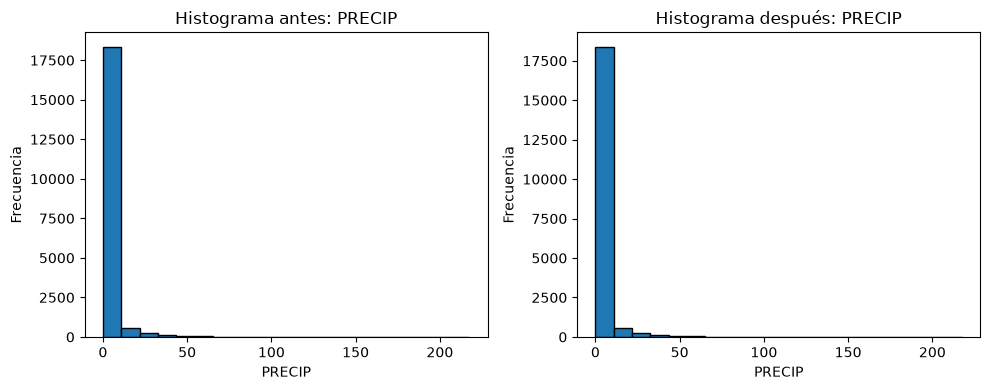

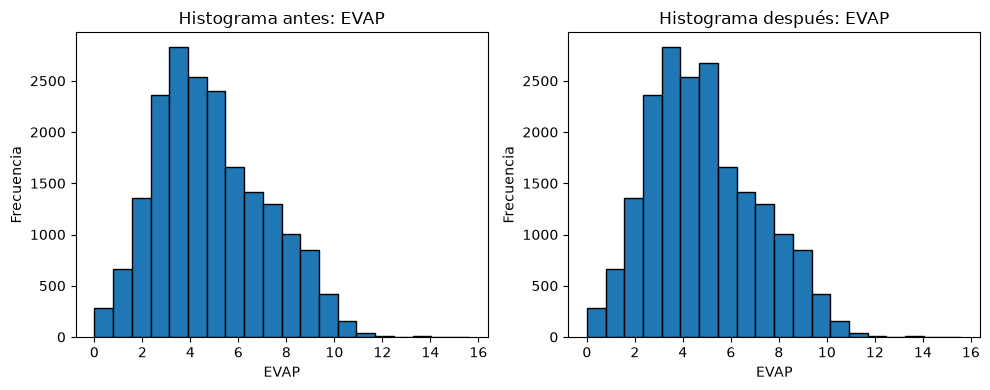

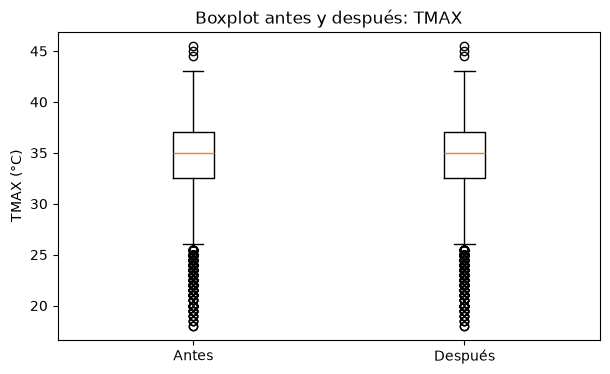

In [8]:
# Comparación visual antes y después de la limpieza
print("--- Histogramas y boxplots antes y después de la limpieza ---")
graficar_histogramas_y_boxplots(df, df_lleno)


## 9. Organización del programa: `main()`

Finalmente reunimos los pasos principales en `main()`: cargar el archivo, contar los registros con faltantes y aplicar la limpieza. La condición `if __name__ == '__main__':` permite ejecutar esa secuencia cuando iniciamos el programa directamente.

Esta función agrupa algunos pasos mostrados anteriormente y demuestra que podemos organizar el proceso completo dentro de una función principal.


In [9]:
def main():
    archivo='25001.txt'
    datos=cargarCSV(archivo)
    contarNulos(datos)
    datos_limpios = limpiar_datos(datos)


## 10. Conclusiones

Identificamos **312 fechas con registros incompletos** y completamos las cuatro variables numéricas con sus respectivas medias. Comparamos tablas, estadísticas y gráficas para comprobar los efectos de la limpieza. Aprendimos a utilizar funciones, ciclos, diccionarios y herramientas de Pandas.

El método es práctico, pero puede alterar la variabilidad; en trabajos futuros podríamos considerar la estacionalidad del clima. En conclusión, es importante explorar primero, limpiar con un criterio explícito y evaluar los cambios antes de realizar análisis posteriores.


In [10]:
if __name__ == "__main__":
    main()

--- Conteo de registros faltantes por fecha ---
Se encontraron 312 fechas con datos faltantes.
Ejemplo de las primeras 5 fechas:
Fecha: 01/01/1961 | Faltantes: 1
Fecha: 02/01/1961 | Faltantes: 1
Fecha: 03/01/1961 | Faltantes: 1
Fecha: 04/01/1961 | Faltantes: 1
Fecha: 05/01/1961 | Faltantes: 1

--- Total de valores nulos por columna ---
FECHA: 0 valores faltantes
PRECIP: 40 valores faltantes
EVAP: 272 valores faltantes
TMAX: 5 valores faltantes
TMIN: 6 valores faltantes
Total de valores nulos: 323
Rellenando nulos con la media de la columna
Columna 'PRECIP': nulos reemplazados con la media -> 2.22 
Columna 'EVAP': nulos reemplazados con la media -> 4.88 
Columna 'TMAX': nulos reemplazados con la media -> 34.47 
Columna 'TMIN': nulos reemplazados con la media -> 16.66 
